# MovieLens 32M — EDA
Проект рекомендательной системы фильмов. Анализ полного датасета.

[Источник и условия использования](https://files.grouplens.org/datasets/movielens/ml-32m-README.html).

## Подготовка данных

Загружаем таблицы для анализа.

In [1]:
# При необходимости: %pip install pandas numpy matplotlib requests
from pathlib import Path
import hashlib, json, zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True})
pd.set_option('display.max_columns', 20)
DATA = Path('data'); DATA.mkdir(exist_ok=True)
URL = 'https://files.grouplens.org/datasets/movielens/ml-32m.zip'
archive = DATA / 'ml-32m.zip'
if not archive.exists():
    temporary = archive.with_suffix('.part')
    with requests.get(URL, stream=True, timeout=(30, 180)) as r:
        r.raise_for_status()
        with temporary.open('wb') as f:
            for chunk in r.iter_content(1024 * 1024): f.write(chunk)
    temporary.replace(archive)
with zipfile.ZipFile(archive) as z:
    for filename in ['ratings.csv', 'movies.csv', 'tags.csv', 'links.csv', 'README.txt']:
        target = DATA / 'ml-32m' / filename
        if not target.exists(): z.extract('ml-32m/' + filename, DATA)
digest = hashlib.sha256()
with archive.open('rb') as f:
    for block in iter(lambda: f.read(1024*1024), b''): digest.update(block)
print('Archive SHA256:', digest.hexdigest())
print('Versions:', pd.__version__, np.__version__)
ratings = pd.read_csv(DATA/'ml-32m/ratings.csv', dtype={'userId':'int32','movieId':'int32','rating':'float32','timestamp':'int64'})
movies = pd.read_csv(DATA/'ml-32m/movies.csv')
tags = pd.read_csv(DATA/'ml-32m/tags.csv')
links = pd.read_csv(DATA/'ml-32m/links.csv')
print({k: len(v) for k,v in {'ratings': ratings, 'movies': movies, 'tags': tags, 'links': links}.items()})

Archive SHA256: e4a68655d7386b8f95f2f2424b2ff975dfdd15ffd59e0d864a14dca43e99d6ee
Versions: 2.3.3 2.0.2


{'ratings': 32000204, 'movies': 87585, 'tags': 2000072, 'links': 87585}


**Вывод.** 32 000 204 оценки, 87 585 объектов каталога, 2 000 072 тега.

## 1. Схема и качество

Ищем ошибки, которые могут исказить обучение.

In [2]:
for name, frame in [('ratings', ratings), ('movies', movies), ('tags', tags), ('links', links)]:
    print(name); display(frame.head(3)); display(frame.isna().sum().to_frame('missing'))
quality = pd.Series({
    'duplicate_rating_rows': int(ratings.duplicated().sum()),
    'duplicate_user_movie': int(ratings.duplicated(['userId','movieId']).sum()),
    'duplicate_movie_keys': int(movies.movieId.duplicated().sum()),
    'ratings_without_metadata': int((~ratings.movieId.isin(movies.movieId)).sum()),
    'invalid_ratings': int((~ratings.rating.isin(np.arange(.5, 5.1, .5))).sum()),
    'missing_genres': int(movies.genres.eq('(no genres listed)').sum()),
    'missing_tag_text': int(tags.tag.isna().sum())})
display(quality.to_frame('count'))
assert quality['invalid_ratings'] == 0
assert ratings[['userId','movieId','timestamp','rating']].notna().all().all()
assert quality['duplicate_movie_keys'] == 0

ratings


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976


,missing
userId,0
movieId,0
rating,0
timestamp,0


movies


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


,missing
movieId,0
title,0
genres,0


... (3 outputs left out)

links


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0


,missing
movieId,0
imdbId,0
tmdbId,124


,count
duplicate_rating_rows,0
duplicate_user_movie,0
duplicate_movie_keys,0
ratings_without_metadata,0
invalid_ratings,0
missing_genres,7080
missing_tag_text,17


**Вывод.** Дубликатов и некорректных оценок нет. Не указан жанр у 7 080 объектов; пусты 17 тегов и 124 tmdbId.

## 2. Плотность, активность и длинный хвост

Оцениваем объём истории и концентрацию популярности.

,value
ratings,3.200020e+07
users,2.009480e+05
rated_movies,8.443200e+04
catalog_movies,8.758500e+04
density,1.886088e-03
catalog_without_ratings,3.153000e+03
top_1pct_movies_rating_share,5.487858e-01
users_with_under_20_ratings_share,0.000000e+00
movies_with_under_5_ratings_share,4.802445e-01


,ratings_per_user,ratings_per_movie
count,200948.000000,84432.000000
mean,159.246193,379.005638
std,282.025462,2592.439791
min,20.000000,1.000000
50%,73.000000,5.000000
90%,364.000000,248.900000
99%,1290.000000,9263.140000
max,33332.000000,102929.000000


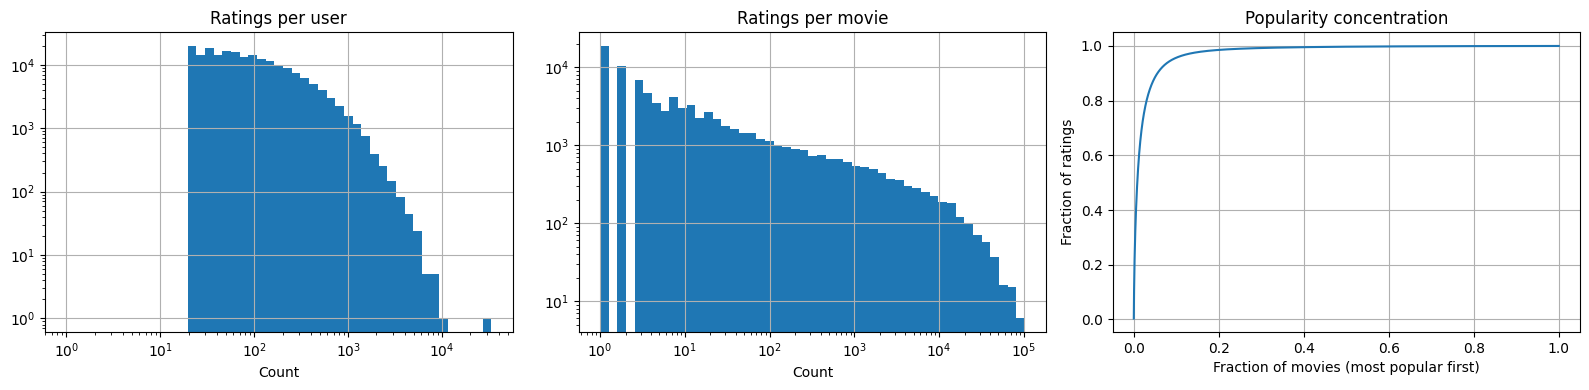

In [3]:
user_counts = ratings.groupby('userId').size()
item_counts = ratings.groupby('movieId').size()
unique_pairs = len(ratings.drop_duplicates(['userId','movieId']))
top_n = max(1, int(np.ceil(len(item_counts)*.01)))
summary = pd.Series({
    'ratings': len(ratings), 'users': len(user_counts), 'rated_movies': len(item_counts),
    'catalog_movies': len(movies), 'density': unique_pairs/(len(user_counts)*len(item_counts)),
    'catalog_without_ratings': int((~movies.movieId.isin(item_counts.index)).sum()),
    'top_1pct_movies_rating_share': item_counts.nlargest(top_n).sum()/len(ratings),
    'users_with_under_20_ratings_share': user_counts.lt(20).mean(),
    'movies_with_under_5_ratings_share': item_counts.lt(5).mean()})
display(summary.to_frame('value'))
display(pd.DataFrame({'ratings_per_user': user_counts.describe(percentiles=[.5,.9,.99]), 'ratings_per_movie': item_counts.describe(percentiles=[.5,.9,.99])}))
fig, axes = plt.subplots(1, 3, figsize=(16,4))
axes[0].hist(user_counts, bins=np.geomspace(1, user_counts.max()+1, 50)); axes[0].set(xscale='log', yscale='log', title='Ratings per user', xlabel='Count')
axes[1].hist(item_counts, bins=np.geomspace(1, item_counts.max()+1, 50)); axes[1].set(xscale='log', yscale='log', title='Ratings per movie', xlabel='Count')
axes[2].plot(np.arange(1,len(item_counts)+1)/len(item_counts), item_counts.sort_values(ascending=False).cumsum()/len(ratings)); axes[2].set(title='Popularity concentration', xlabel='Fraction of movies (most popular first)', ylabel='Fraction of ratings')
plt.tight_layout(); plt.show()

**Вывод.** Разреженность — 99,81%. 1% фильмов собирает 54,88% оценок; у 48,02% фильмов меньше пяти оценок. В каталоге 3 153 объекта без оценок. Все пользователи имеют минимум 20 оценок.

## 3. Оценки и популярные фильмы

Проверяем распределение оценок и основу для базовой модели.

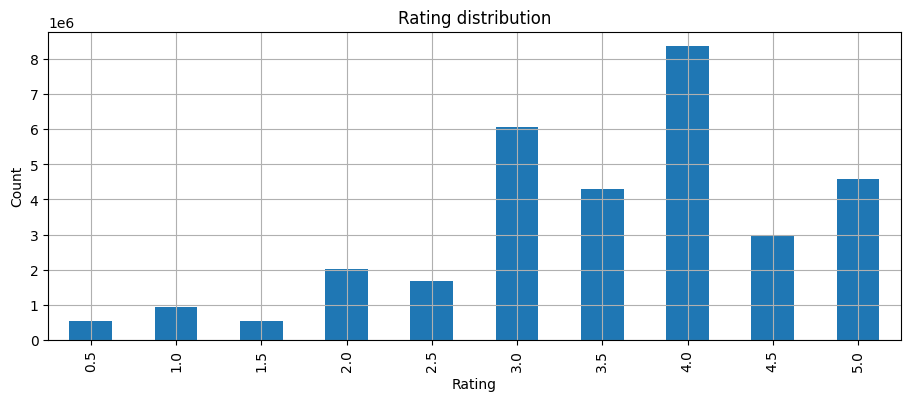

,title,genres,size,mean
movieId,,,,
318,"Shawshank Redemption, The (1994)",Crime|Drama,102929,4.404614
356,Forrest Gump (1994),Comedy|Drama|Romance|War,100296,4.052744
296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,98409,4.196969
2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,93808,4.156436
593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,90330,4.148367
260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,85010,4.099823
2959,Fight Club (1999),Action|Crime|Drama|Thriller,77332,4.228780
480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,75233,3.698623
527,Schindler's List (1993),Drama|War,73849,4.236990


,title,size,mean
movieId,,,
171011,Planet Earth II (2016),1956,4.446830
159817,Planet Earth (2006),2948,4.444369
170705,Band of Brothers (2001),2811,4.426538
318,"Shawshank Redemption, The (1994)",102929,4.404614
171495,Cosmos,615,4.330081
858,"Godfather, The (1972)",66440,4.317030
202439,Parasite (2019),11670,4.312253
179135,Blue Planet II (2017),1163,4.300086
198185,Twin Peaks (1989),1140,4.298684


Global mean rating: 3.540395736694336


In [4]:
ratings.rating.value_counts().sort_index().plot.bar(title='Rating distribution', xlabel='Rating', ylabel='Count'); plt.show()
item_stats = ratings.groupby('movieId').rating.agg(['size','mean','std']).join(movies.set_index('movieId'))
display(item_stats.nlargest(15, 'size')[['title','genres','size','mean']])
display(item_stats[item_stats['size'] >= 100].nlargest(15,'mean')[['title','size','mean']])
print('Global mean rating:', float(ratings.rating.mean()))

**Вывод.** Средняя оценка — 3,54. У «Побега из Шоушенка» больше всего оценок: 102 929. В каталоге есть также сериалы и документальные проекты.

## 4. Жанры и метаданные

Оцениваем признаки для рекомендаций по содержанию.

,catalog_movies,ratings
genre,,
Drama,34175,13973271.0
Comedy,23124,11206926.0
Action,9668,9665213.0
Thriller,11823,8679464.0
Adventure,5402,7590522.0
Sci-Fi,4907,5717337.0
Romance,10369,5524615.0
Crime,6976,5373051.0
Fantasy,3851,3702759.0


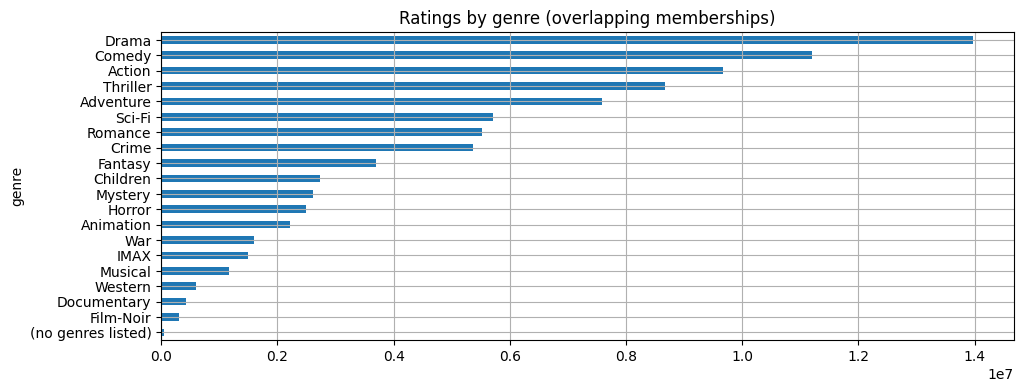

Titles without parsed year: 771


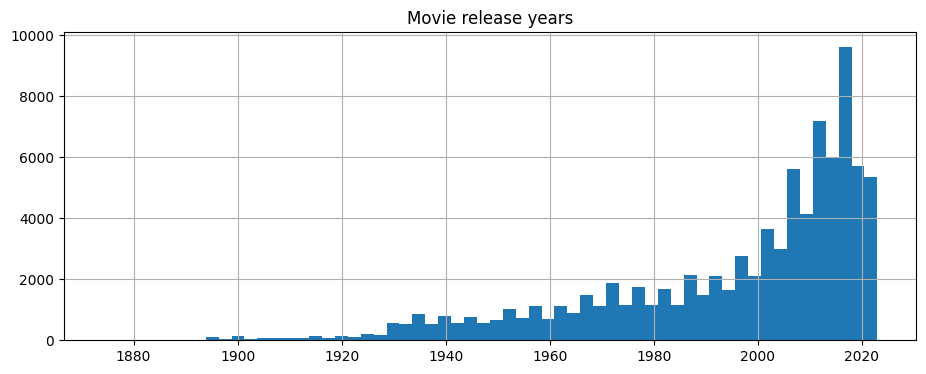

Movies with tags: 51323 Users providing tags: 15848
Rated movie tag coverage: 0.5705182869054387


,tag_count
tag,
sci-fi,11437
atmospheric,10088
action,9337
comedy,8784
funny,8088
surreal,7480
visually appealing,7253
based on a book,6728
twist ending,6600


In [5]:
genre_rows = movies.assign(genre=movies.genres.str.split('|')).explode('genre')
genre_stats = genre_rows.groupby('genre').size().to_frame('catalog_movies')
genre_stats['ratings'] = genre_rows.assign(n=genre_rows.movieId.map(item_counts).fillna(0)).groupby('genre').n.sum()
display(genre_stats.sort_values('ratings', ascending=False))
genre_stats.ratings.sort_values().plot.barh(title='Ratings by genre (overlapping memberships)'); plt.show()
years = pd.to_numeric(movies.title.str.extract(r'\((\d{4})\)$', expand=False), errors='coerce')
print('Titles without parsed year:', years.isna().sum())
years.hist(bins=60); plt.title('Movie release years'); plt.show()
print('Movies with tags:', tags.movieId.nunique(), 'Users providing tags:', tags.userId.nunique())
print('Rated movie tag coverage:', item_counts.index.isin(tags.movieId.unique()).mean())
display(tags.tag.dropna().str.lower().value_counts().head(20).to_frame('tag_count'))

**Вывод.** По числу оценок лидируют Drama, Comedy и Action; жанры пересекаются. Теги покрывают 57,05% оценённых объектов; год не извлечён у 771 записи.

## 5. Время и холодный старт

Делим данные по времени и измеряем холодный старт.

UTC range: 1995-01-09 11:46:44+00:00 2023-10-13 02:29:07+00:00


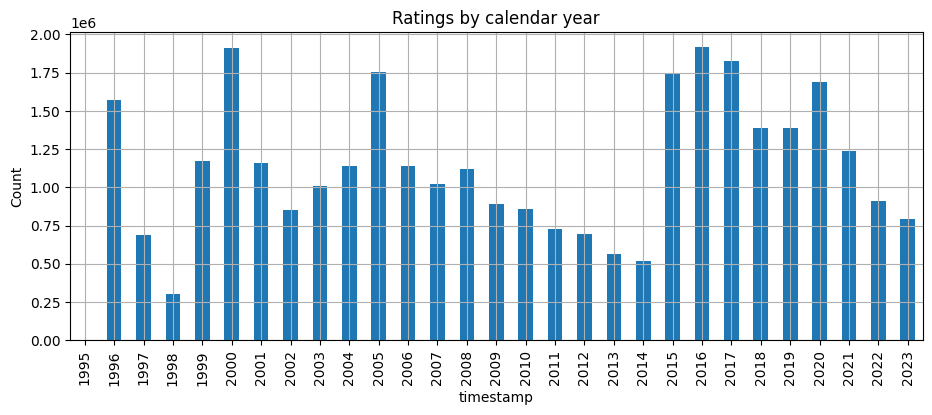

,split,rows,from_utc,to_utc,new_user_event_share,new_item_event_share
0,train,25600163,1995-01-09 11:46:44+00:00,2018-10-03 07:21:40+00:00,0.000000,0.000000
1,validation,3200020,2018-10-03 07:21:45+00:00,2020-11-05 19:45:33+00:00,0.821373,0.061575
2,test,3200021,2020-11-05 19:45:35+00:00,2023-10-13 02:29:07+00:00,0.856694,0.138057


Training tags available by cutoff: 893500


In [6]:
dates = pd.to_datetime(ratings.timestamp, unit='s', utc=True)
print('UTC range:', dates.min(), dates.max())
dates.dt.year.value_counts().sort_index().plot.bar(title='Ratings by calendar year', ylabel='Count'); plt.show()
t1, t2 = ratings.timestamp.quantile([.8,.9]).astype('int64')
train_mask = ratings.timestamp <= t1
val_mask = (ratings.timestamp > t1) & (ratings.timestamp <= t2)
test_mask = ratings.timestamp > t2
train_users = ratings.loc[train_mask,'userId'].unique()
train_items = ratings.loc[train_mask,'movieId'].unique()
rows=[]
for name, mask in [('train',train_mask),('validation',val_mask),('test',test_mask)]:
    part=ratings.loc[mask]
    rows.append({'split':name,'rows':len(part),'from_utc':pd.to_datetime(part.timestamp.min(),unit='s',utc=True), 'to_utc':pd.to_datetime(part.timestamp.max(),unit='s',utc=True), 'new_user_event_share':(~part.userId.isin(train_users)).mean(),'new_item_event_share':(~part.movieId.isin(train_items)).mean()})
split_report = pd.DataFrame(rows); display(split_report)
assert sum(x['rows'] for x in rows) == len(ratings)
print('Training tags available by cutoff:', int((tags.timestamp <= t1).sum()))

**Вывод.** В тесте 85,67% событий от новых пользователей и 13,81% с новыми фильмами. Персонализацию нужно проверять отдельно на знакомых пользователях и фильмах.

## 6. Средняя оценка и число оценок фильма

Проверяем надёжность средней оценки при малом числе наблюдений.

,movies,median_mean,p10,p90,perfect_mean_share
group,,,,,
1–4,40548,3.000000,1.500000,4.000000,0.035637
5–19,20534,3.045455,2.200000,3.666667,0.000000
20–99,11159,3.181818,2.517857,3.652174,0.000000
100–999,7794,3.309821,2.594947,3.773568,0.000000
1000+,4397,3.472853,2.745908,3.944034,0.000000


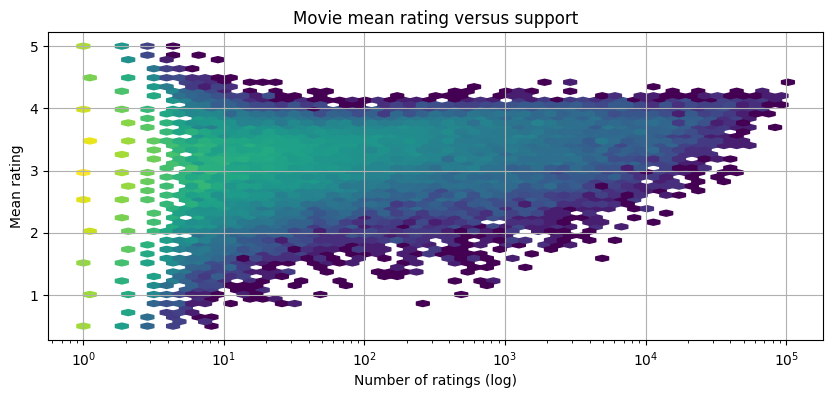

Spearman correlation: 0.1549031883043511


In [7]:
support = item_stats[['size','mean']].copy()
support['group'] = pd.cut(support['size'], [0,4,19,99,999,np.inf], labels=['1–4','5–19','20–99','100–999','1000+'])
support_table = support.groupby('group', observed=True).agg(movies=('mean','size'), median_mean=('mean','median'), p10=('mean',lambda x:x.quantile(.1)), p90=('mean',lambda x:x.quantile(.9)), perfect_mean_share=('mean',lambda x:x.eq(5).mean()))
display(support_table)
fig, ax = plt.subplots(figsize=(10,4))
ax.hexbin(support['size'],support['mean'],xscale='log',gridsize=55,bins='log',mincnt=1)
ax.set(xlabel='Number of ratings (log)',ylabel='Mean rating',title='Movie mean rating versus support'); plt.show()
mean_count_corr = support['size'].rank().corr(support['mean'].rank())
print('Spearman correlation:', mean_count_corr)


**Вывод.** Корреляция числа оценок со средней — 0,155. Среди фильмов с 1–4 оценками 3,56% имеют среднюю 5. Для рейтинга нужен учёт числа наблюдений; порог 100 требует проверки.

## 7. Различия в оценках пользователей

Проверяем различия в пользовательских средних оценках.

,user_mean_rating
count,200948.000000
mean,3.704369
std,0.486573
min,0.500000
10%,3.111111
50%,3.725000
90%,4.293103
max,5.000000


,users,median_mean,median_std
activity,,,
20–49,72604,3.777778,0.906962
50–199,86147,3.768041,0.887803
200–999,38576,3.577959,0.890965
1000+,3621,3.290801,0.889009


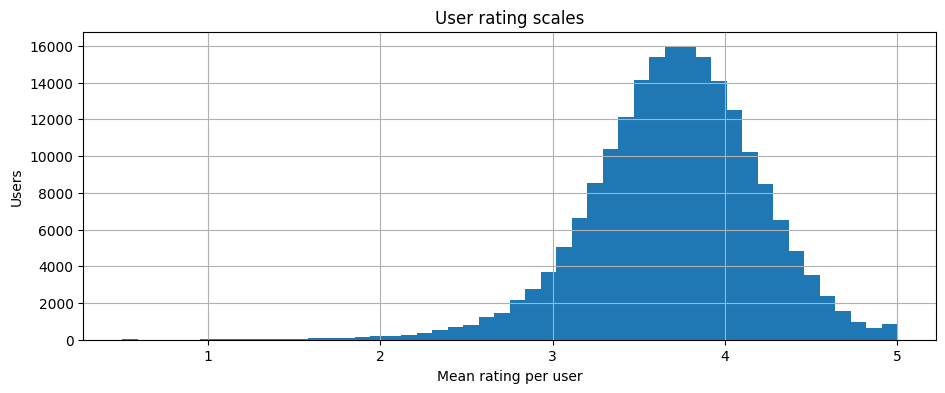

In [8]:
user_stats = ratings.groupby('userId').rating.agg(['size','mean','std'])
display(user_stats['mean'].describe(percentiles=[.1,.5,.9]).to_frame('user_mean_rating'))
user_stats['activity'] = pd.cut(user_stats['size'],[0,49,199,999,np.inf],labels=['20–49','50–199','200–999','1000+'])
display(user_stats.groupby('activity',observed=True).agg(users=('mean','size'),median_mean=('mean','median'),median_std=('std','median')))
user_stats['mean'].hist(bins=50); plt.xlabel('Mean rating per user'); plt.ylabel('Users'); plt.title('User rating scales'); plt.show()


**Вывод.** 10-й, 50-й и 90-й процентили пользовательских средних — 3,11 / 3,72 / 4,29. Различия могут отражать шкалу оценивания и выбор фильмов.

## 8. Сравнение временных частей

Проверяем различия между обучением, валидацией и тестом.

,ratings,users,movies,mean_rating,positive_share,median_events_per_user,train_catalog_event_share
split,,,,,,,
train,25600163,170491,50977,3.531869,0.498387,70.0,1.000000
validation,3200020,22919,54803,3.589028,0.505462,67.0,0.938425
test,3200021,22252,63300,3.559970,0.488109,66.0,0.861943


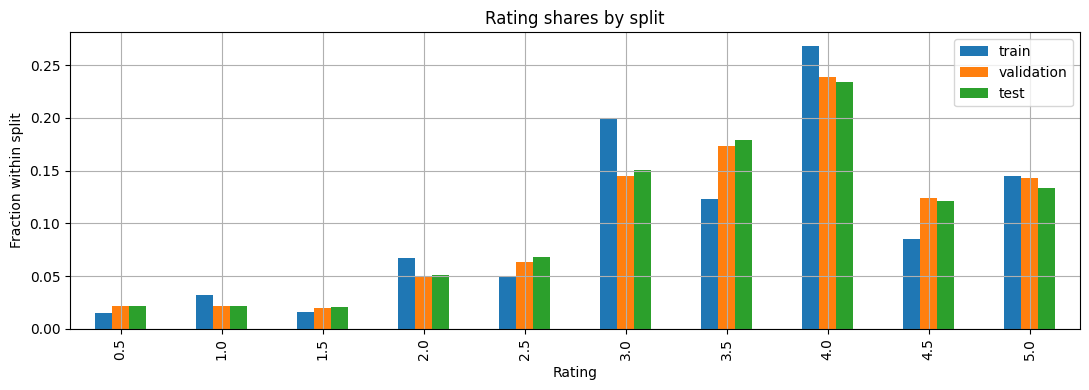

Activity measured within each period; periods have different durations.


In [9]:
periods = [('train',train_mask),('validation',val_mask),('test',test_mask)]
shift_rows=[]; distributions={}
for name, mask in periods:
    part=ratings.loc[mask]
    counts=part.groupby('userId').size()
    shift_rows.append({'split':name,'ratings':len(part),'users':part.userId.nunique(),'movies':part.movieId.nunique(),'mean_rating':part.rating.mean(),'positive_share':part.rating.ge(4).mean(),'median_events_per_user':counts.median(),'train_catalog_event_share':part.movieId.isin(train_items).mean()})
    distributions[name]=part.rating.value_counts(normalize=True).sort_index()
shift=pd.DataFrame(shift_rows).set_index('split'); display(shift)
pd.DataFrame(distributions).plot.bar(title='Rating shares by split',ylabel='Fraction within split',xlabel='Rating'); plt.tight_layout(); plt.show()
print('Activity measured within each period; periods have different durations.')


**Вывод.** Средние train / validation / test — 3,53 / 3,59 / 3,56; доли оценок ≥ 4 — 49,84% / 50,55% / 48,81%. Активность измерена за периоды разной длины.

## 9. Группа для оценки персонализации

Считаем группу для проверки персонализации без холодного старта.

In [10]:
warm_rows=[]
for name, mask in [('validation',val_mask),('test',test_mask)]:
    part=ratings.loc[mask]
    known_user=part.userId.isin(train_users)
    known_item=part.movieId.isin(train_items)
    warm=known_user & known_item
    positive=part.rating.ge(4)
    warm_positive=part.loc[warm & positive]
    users=warm_positive.groupby('userId').size()
    warm_rows.append({'split':name,'all_events':len(part),'known_user_known_item_events':int(warm.sum()),'warm_event_share':warm.mean(),'warm_positive_events':len(warm_positive),'eligible_users':len(users),'median_relevant_movies':users.median(),'eligible_share_of_period_users':len(users)/part.userId.nunique()})
warm_report=pd.DataFrame(warm_rows).set_index('split'); display(warm_report)
assert warm_report.eligible_users.gt(0).all()
# There are no repeated user–movie pairs, so these target films were not rated by the user in train.
assert not ratings.duplicated(['userId','movieId']).any()
print('Positive target: rating >= 4. Known user/item: observed in train. Targets are unique unseen pairs.')


,all_events,known_user_known_item_events,warm_event_share,warm_positive_events,eligible_users,median_relevant_movies,eligible_share_of_period_users
split,,,,,,,
validation,3200020,480907,0.150282,193119,6428,14.0,0.280466
test,3200021,312952,0.097797,119269,4310,11.0,0.193690


Positive target: rating >= 4. Known user/item: observed in train. Targets are unique unseen pairs.


**Вывод.** При обучении только на train: 6 428 подходящих пользователей в validation, 4 310 в test. В тесте 119 269 положительных целей (оценка ≥ 4), медиана — 11 на пользователя.